# Waze vs the incident register · checkpoint 2

Catch-up notebook: one way to get here, with its output. Done so far: times in local time, alerts placed on the AP-34 with PK and direction.

Run all the cells (Runtime › Run all), then continue the exercise from the end of this notebook with your own code.

In [1]:
# The tools for today: pandas for tables, geopandas for maps and distances, matplotlib for plots.
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Where the data files are: next to the notebook if there is a data folder,
# otherwise read straight from the course repository on GitHub (this is the case in Colab).
DATA = "https://raw.githubusercontent.com/daniel-verdugo/upm-data-integration/main/3.1-data-integration/session14/data/"
if os.path.isdir("data"):
    DATA = "data/"
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 150   # sharper plots
pd.set_option("display.max_columns", 30)

## 1 · The feed: what is one row?

One line of `waze_feed.jsonl` is one poll of the partner feed, every 5 minutes, exactly as Waze
returns it. Field meanings: the official *Waze Data Feed specifications*
(https://support.google.com/waze/partners/answer/13458165).

In [2]:
# Read the Waze feed. The file has one JSON object per line, and each line is one poll.
# shape tells me how many polls (rows) and fields (columns) I have.
polls = pd.read_json(DATA + "waze_feed.jsonl", lines=True)
polls.shape

(12096, 6)

In [3]:
# A first look: each poll has its time window and, inside, a list of alerts and a list of jams.
polls.head()

,endTimeMillis,startTimeMillis,startTime,endTime,alerts,jams
0,1769986835790,1769986775790,2026-02-01 22:59:35:000,2026-02-01 23:00:35:000,NaN,NaN
1,1769987131479,1769987071479,2026-02-01 23:04:31:000,2026-02-01 23:05:31:000,NaN,NaN
2,1769987435609,1769987375609,2026-02-01 23:09:35:000,2026-02-01 23:10:35:000,NaN,NaN
3,1769987730105,1769987670105,2026-02-01 23:14:30:000,2026-02-01 23:15:30:000,NaN,NaN
4,1769988038087,1769987978087,2026-02-01 23:19:38:000,2026-02-01 23:20:38:000,NaN,NaN


Each poll carries a list of alerts. `explode` gives one row per alert in a poll:

In [4]:
# I want one row per alert. explode splits each list of alerts into separate rows.
# Polls without alerts leave an empty row, so I drop those.
alert_rows = polls[["endTimeMillis", "alerts"]].explode("alerts")
alert_rows = alert_rows.dropna(subset=["alerts"])
alert_rows.shape

(7618, 2)

In [5]:
# Each alert is still a dictionary. json_normalize turns its fields into columns
# (location becomes location.x and location.y). I also keep the poll time, to know when it was seen.
alerts = pd.json_normalize(alert_rows["alerts"].tolist())
alerts["poll_ms"] = alert_rows["endTimeMillis"].values
alerts.head()

,country,reportRating,reportByMunicipalityUser,reliability,type,uuid,roadType,magvar,subtype,pubMillis,confidence,nThumbsUp,street,location.x,location.y,poll_ms
0,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769989535119
1,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769989838479
2,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769990130332
3,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769990435299
4,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769990735345


In [6]:
# How many different alerts are there really? Fewer than rows: the same uuid repeats.
alerts["uuid"].nunique()

1129

One row is **one alert in one poll**. An alert stays in the feed while it is active, so the same
`uuid` appears in many polls, and its `reliability` and `confidence` change along the way.

In [7]:
# In how many polls does each alert appear? This confirms the grain: one alert in one poll.
alerts.groupby("uuid").size().describe()

count    1129.000000
mean        6.747564
std         4.421403
min         1.000000
25%         3.000000
50%         6.000000
75%        10.000000
max        24.000000
dtype: float64

## 2 · From polls to alerts (one row per `uuid`)

In [8]:
# Now one row per alert. I group the rows of each uuid and keep the first value of the fields
# that do not change, the first and last poll it was seen in, and the highest reliability
# and confidence it reached.
ev = alerts.sort_values("poll_ms").groupby("uuid").agg(
    type=("type", "first"),
    subtype=("subtype", "first"),
    street=("street", "first"),
    pubMillis=("pubMillis", "first"),
    first_poll=("poll_ms", "min"),
    last_poll=("poll_ms", "max"),
    reliability=("reliability", "max"),
    confidence=("confidence", "max"),
    x=("location.x", "first"),
    y=("location.y", "first"),
    magvar=("magvar", "first"),
)
len(ev)

1129

In [9]:
# What kinds of alerts are there? Many of them are probably not incidents the operator logs.
ev.groupby(["type", "subtype"]).size().sort_values(ascending=False)

type      subtype                       
HAZARD    HAZARD_ON_SHOULDER_CAR_STOPPED    430
          HAZARD_ON_ROAD_LANE_CLOSED        110
          HAZARD_ON_ROAD_CAR_STOPPED         94
          HAZARD_ON_ROAD_CONSTRUCTION        88
JAM       JAM_HEAVY_TRAFFIC                  71
HAZARD    HAZARD_ON_ROAD_OBJECT              67
ACCIDENT                                     54
JAM       JAM_STAND_STILL_TRAFFIC            53
                                             48
HAZARD    HAZARD_ON_ROAD                     32
          HAZARD_WEATHER_FOG                 28
          HAZARD_WEATHER                     18
          HAZARD_ON_ROAD_POT_HOLE            14
ACCIDENT  ACCIDENT_MAJOR                     10
HAZARD    HAZARD_ON_SHOULDER_ANIMALS          9
ACCIDENT  ACCIDENT_MINOR                      3
dtype: int64

## 3 · Time: epoch milliseconds in UTC

`pubMillis` is milliseconds since 1970 in UTC. The register is in local time (Madrid, UTC+1 in
February and March), without a zone.

In [10]:
# pubMillis is milliseconds since 1970, in UTC. I turn it into a date and tell pandas it is UTC.
pub_utc = pd.to_datetime(ev["pubMillis"], unit="ms", utc=True)
pub_utc.head()

uuid
00831f45-df44-4a29-bd5b-0d5eb76aaa52   2026-02-25 16:01:17.640000+00:00
00fb3c8f-2173-4ed4-94af-83da1a43f662   2026-02-28 16:40:07.441000+00:00
0108fce1-3f67-477a-94eb-2245f5ba64aa   2026-03-15 15:31:32.078000+00:00
0132eb42-8938-470a-9528-1794fee8603a   2026-02-02 08:57:48.313000+00:00
01776005-fe3d-425f-a865-00a6dc56801f   2026-02-05 22:47:34.272000+00:00
Name: pubMillis, dtype: datetime64[ns, UTC]

In [11]:
# Same instant, Madrid clock: in February it shows one hour more than UTC.
pub_madrid = pub_utc.dt.tz_convert("Europe/Madrid")
pub_madrid.head()

uuid
00831f45-df44-4a29-bd5b-0d5eb76aaa52   2026-02-25 17:01:17.640000+01:00
00fb3c8f-2173-4ed4-94af-83da1a43f662   2026-02-28 17:40:07.441000+01:00
0108fce1-3f67-477a-94eb-2245f5ba64aa   2026-03-15 16:31:32.078000+01:00
0132eb42-8938-470a-9528-1794fee8603a   2026-02-02 09:57:48.313000+01:00
01776005-fe3d-425f-a865-00a6dc56801f   2026-02-05 23:47:34.272000+01:00
Name: pubMillis, dtype: datetime64[ns, Europe/Madrid]

In [12]:
# The register uses local times with no zone, so I drop the zone to be able to compare them.
# I do the same for the first and last time each alert was seen.
# I also keep the UTC version, only to show later what happens if this step is forgotten.
ev["pub"] = pub_madrid.dt.tz_localize(None)
ev["pub_utc"] = pub_utc.dt.tz_localize(None)   # kept only to show the classic mistake in section 7
ev["first_seen"] = pd.to_datetime(ev["first_poll"], unit="ms", utc=True).dt.tz_convert("Europe/Madrid").dt.tz_localize(None)
ev["last_seen"] = pd.to_datetime(ev["last_poll"], unit="ms", utc=True).dt.tz_convert("Europe/Madrid").dt.tz_localize(None)
ev[["pub", "first_seen", "last_seen"]].head()

,pub,first_seen,last_seen
uuid,,,
00831f45-df44-4a29-bd5b-0d5eb76aaa52,2026-02-25 17:01:17.640,2026-02-25 17:05:31.010,2026-02-25 17:55:35.621
00fb3c8f-2173-4ed4-94af-83da1a43f662,2026-02-28 17:40:07.441,2026-02-28 17:50:33.018,2026-02-28 18:10:35.444
0108fce1-3f67-477a-94eb-2245f5ba64aa,2026-03-15 16:31:32.078,2026-03-15 16:45:34.683,2026-03-15 16:45:34.683
0132eb42-8938-470a-9528-1794fee8603a,2026-02-02 09:57:48.313,2026-02-02 10:05:36.849,2026-02-02 11:00:30.043
01776005-fe3d-425f-a865-00a6dc56801f,2026-02-05 23:47:34.272,2026-02-05 23:50:32.510,2026-02-06 00:10:33.960


In [13]:
# How long does an alert stay in the feed? Last seen minus first seen, in minutes.
ev["minutes_alive"] = (ev["last_seen"] - ev["first_seen"]).dt.total_seconds() / 60
ev["minutes_alive"].describe()

count    1129.000000
mean       28.737577
std        22.107458
min         0.000000
25%        10.075350
50%        24.931700
75%        44.904000
max       114.940417
Name: minutes_alive, dtype: float64

## 4 · Where is each alert? From lon/lat to road, PK and direction

`street` is not reliable: missing, written in several ways, and the feed polygon also covers the
old national road.

In [14]:
# Can the street name tell me which alerts are on the motorway? Let me see what it contains.
ev["street"].value_counts(dropna=False)

street
AP-34                842
N-334                123
None                  94
AP34                  56
Salida 42 · AP-34     14
Name: count, dtype: int64

In [15]:
# The motorway axis: a single line, with PK 42 at its first point.
road = gpd.read_file(DATA + "eje.geojson")
road

,road,pk_start,pk_end,geometry
0,AP-34,42.0,57.0,"LINESTRING (-5.05 41.62, -5.04882 41.62019, -5..."


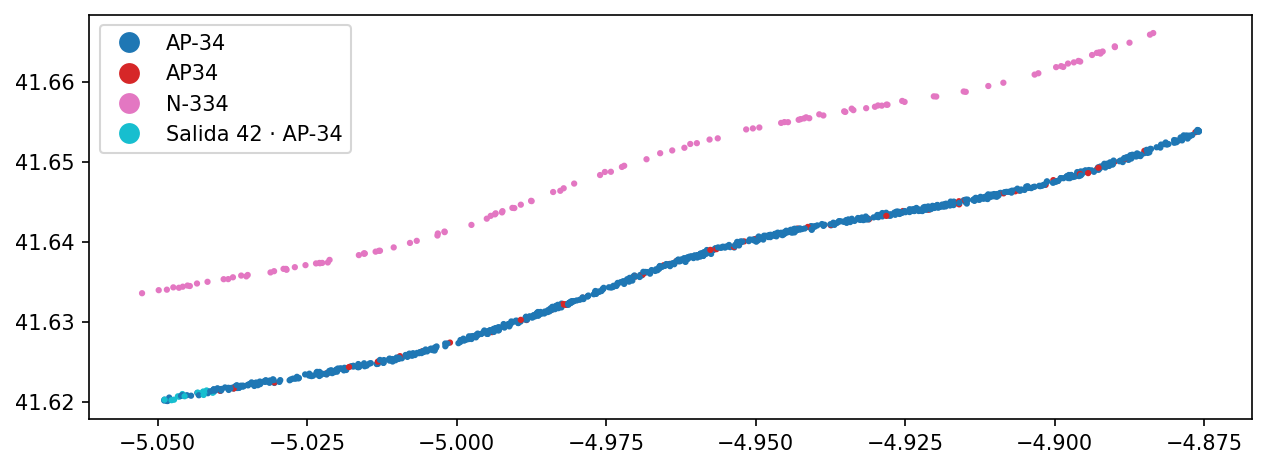

In [16]:
# I turn each alert into a point on the map (longitude, latitude: EPSG:4326) and colour it by
# street, to see where each street value really is.
points = gpd.GeoDataFrame(ev, geometry=gpd.points_from_xy(ev["x"], ev["y"]), crs=4326)
points.plot(column="street", legend=True, markersize=4, figsize=(10, 4))
plt.show()

Distances need metres, so both layers go to EPSG:25830 (ETRS89 / UTM 30N). Then each point is
projected on the road line: the distance along the line is the PK, the distance to the line says
whether the point is on the AP-34 at all.

In [17]:
# To measure in metres, I move both layers to EPSG:25830 (UTM zone 30, in metres).
# line is the axis itself, the geometry I measure against.
points = points.to_crs(25830)
road = road.to_crs(25830)
line = road.geometry.iloc[0]

In [18]:
# For each alert: how far it is from the axis (metres), and how far along the axis it falls.
# The distance along the line, in km, plus 42 is the PK.
points["dist_m"] = points.distance(line)
points["pk"] = 42 + points.geometry.apply(line.project) / 1000
points[["street", "dist_m", "pk"]].head()

,street,dist_m,pk
uuid,,,
00831f45-df44-4a29-bd5b-0d5eb76aaa52,N-334,1505.389992,43.888866
00fb3c8f-2173-4ed4-94af-83da1a43f662,None,1507.320257,53.387114
0108fce1-3f67-477a-94eb-2245f5ba64aa,AP-34,30.507159,43.334046
0132eb42-8938-470a-9528-1794fee8603a,AP-34,11.277251,49.725718
01776005-fe3d-425f-a865-00a6dc56801f,AP-34,13.408520,50.167797


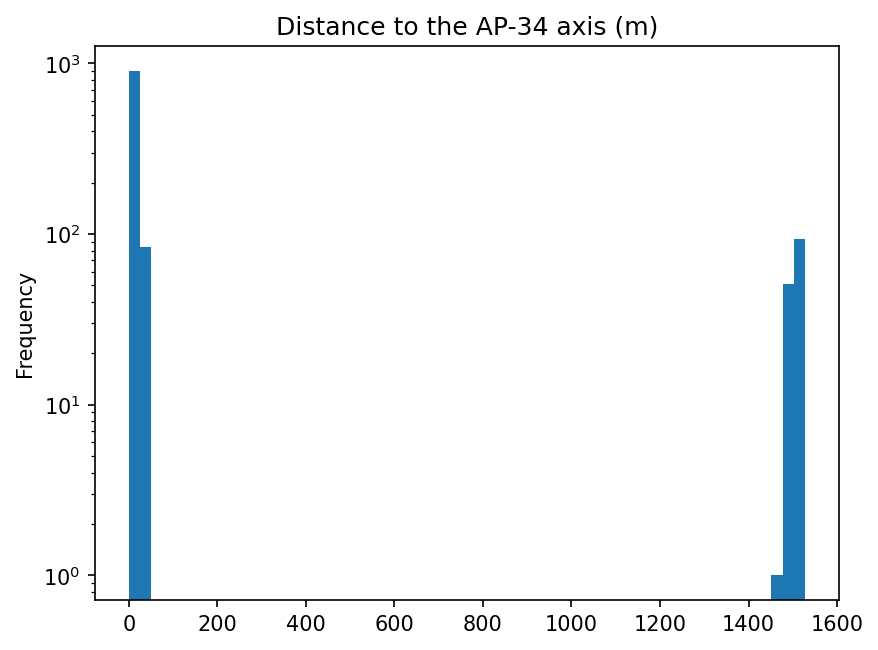

In [19]:
# Are there alerts far from the motorway? A histogram of the distances shows the groups.
# Log scale, so that a small group is still visible.
points["dist_m"].plot.hist(bins=60, log=True, title="Distance to the AP-34 axis (m)")
plt.show()

In [20]:
# Keep the alerts within 100 m of the axis: those are on the motorway.
# Any cut between the two groups of the histogram gives the same result.
on_road = points[points["dist_m"] < 100].copy()
len(on_road)

984

In [21]:
# Check: which street names are left? Only spellings of the motorway, and missing names.
on_road["street"].value_counts(dropna=False)

street
AP-34                842
None                  72
AP34                  56
Salida 42 · AP-34     14
Name: count, dtype: int64

Direction: both carriageways are a few metres apart, so position cannot tell them apart.
`magvar` is the driver's heading (0 = north). The stretch runs roughly east-north-east.

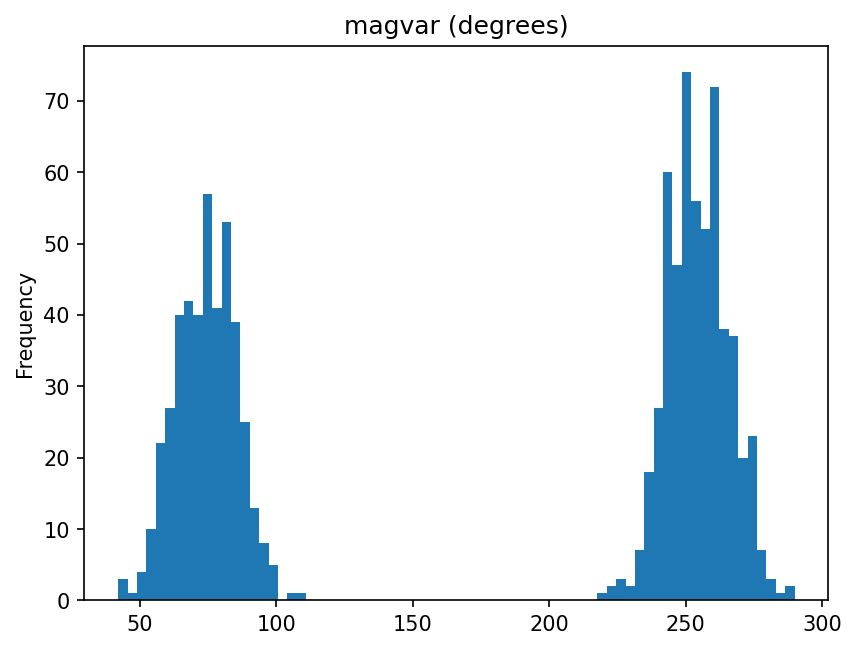

In [22]:
# Which carriageway? Position cannot tell: they are a few metres apart. magvar is the driver's
# heading when reporting; if the histogram shows two peaks, they are the two directions.
on_road["magvar"].plot.hist(bins=72, title="magvar (degrees)")
plt.show()

In [23]:
# The road heads roughly east-north-east (about 75 degrees). Headings below 180 go towards
# higher PKs (Creciente), the rest the other way. I set everything to Decreciente, then overwrite.
on_road["sentido"] = "Decreciente"
on_road.loc[on_road["magvar"] < 180, "sentido"] = "Creciente"
on_road["sentido"].value_counts()

sentido
Decreciente    552
Creciente      432
Name: count, dtype: int64

**End of checkpoint 2.** From here on, the work is yours.